# Training a model on Pangeo CMIP6 data

This notebook shows how monthly CMIP6 data from the Pangeo cloud archive can be used in a `pyearthtools` training workflow. It is a technical demonstration, not a useful model: a small CNN learns to predict the next month of near-surface air temperature (`tas`) from the current month.

It uses the `PangeoCMIP6` accessor from the `Pangeo_CMIP6.ipynb` notebook and needs network access to Google Cloud storage. Training runs on CPU.

In [1]:
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from lightning import LightningModule
from lightning.pytorch.callbacks import RichProgressBar

import pyearthtools.data
import pyearthtools.pipeline
import pyearthtools.pipeline.operations.xarray.normalisation
import pyearthtools.training
from site_archive_pangeo.pangeo_cmip6 import PangeoCMIP6

## Configuration

The data subset is configured by a list of variables and start and end dates. The end date of each split is exclusive. `norm_mean` and `norm_std` are fixed values in the converted unit (`degC`) that bring `tas` to a range suitable for training.

In [2]:
variables = ['tas']

train_start = '2000-01'
train_end = '2005-01'
val_start = '2005-01'
val_end = '2006-01'

norm_mean = 4.0
norm_std = 15.0

batch_size = 4
max_epochs = 3

workdir = Path('pangeo_cmip6_training')

## Data preparation pipeline

The pipeline reads one month from the archive, converts the unit from kelvin to degrees Celsius, drops the scalar `height` coordinate and normalises the values. `TemporalRetrieval` with `delta_unit='month'` then returns the current month as model input and the next month as target. The sample is converted to NumPy and the length-one time axis removed. A cache avoids downloading the same month again in every epoch.

In [3]:
class ConvertUnits(pyearthtools.data.Transform):
    '''
    This transform converts the unit in a dataset.
    '''
    def __init__(self, var_convert_dict, var_units):
        self._var_convert_dict = var_convert_dict
        self._var_units = var_units
        if set(var_convert_dict.keys()) != set(var_units.keys()):
            raise ValueError('The unit conversion function and unit names dictionaries must have the same keys.')
        super().__init__()
        self.record_initialisation()

    def apply(self, sample):
        def map_func(da, var_lut):
            try:
                ret_val = var_lut[da.name](da)
            except KeyError:
                ret_val = da
            return ret_val

        ret_sample = sample.map(map_func, var_lut=self._var_convert_dict)
        for var_name, var_unit in self._var_units.items():
            ret_sample[var_name].attrs['units'] = var_unit
        return ret_sample

In [4]:
data_preparation = pyearthtools.pipeline.Pipeline(
    PangeoCMIP6(variables, source_id='CanESM5', experiment_id='historical'),
    ConvertUnits(var_convert_dict={'tas': lambda a: a - 273.15}, var_units={'tas': 'degC'}),
    pyearthtools.data.transforms.coordinates.Drop('height', ignore_missing=True),
    pyearthtools.pipeline.operations.xarray.normalisation.Deviation(mean=norm_mean, deviation=norm_std),
    pyearthtools.pipeline.modifications.TemporalRetrieval(concat=True, samples=((0, 1), (1, 1)), delta_unit='month'),
    pyearthtools.pipeline.operations.xarray.conversion.ToNumpy(),
    pyearthtools.pipeline.operations.numpy.reshape.Squeeze(axis=0),
    pyearthtools.pipeline.modifications.Cache(workdir / 'cache', pattern_kwargs={'extension': 'npy'}),
)

input_sample, target_sample = data_preparation[train_start]
print('Input shape:', input_sample.shape)
print('Target shape:', target_sample.shape)

Input shape: (1, 64, 128)
Target shape: (1, 64, 128)


## Train and validation splits

Each split is a range of months. The training months are visited in random order.

In [5]:
train_split = pyearthtools.pipeline.iterators.DateRange(train_start, train_end, interval='1 month').randomise(seed=42)
val_split = pyearthtools.pipeline.iterators.DateRange(val_start, val_end, interval='1 month')
print('Train months:', train_split[:5])
print('Validation months:', val_split[:5])

Calculated indexes
Train months: (Petdt('2003-08'), Petdt('2002-10'), Petdt('2000-04'), Petdt('2003-09'), Petdt('2002-02'))
Validation months: (Petdt('2005-01'), Petdt('2005-02'), Petdt('2005-03'), Petdt('2005-04'), Petdt('2005-05'))


## Model

A small convolutional network that maps the field of one month to the field of the next.

In [6]:
class CNN(LightningModule):
    def __init__(self, *, n_features, layer_sizes, learning_rate):
        super().__init__()
        self.save_hyperparameters()

        sizes = (n_features,) + tuple(layer_sizes)
        layers = []
        for chan_in, chan_out in zip(sizes[:-1], sizes[1:]):
            layers.extend([nn.Conv2d(chan_in, chan_out, kernel_size=3, padding=1), nn.ReLU()])
        layers.append(nn.Conv2d(sizes[-1], n_features, kernel_size=3, padding=1))
        self.cnn = nn.Sequential(*layers)
        self.learning_rate = learning_rate

    def forward(self, x):
        return self.cnn(x)

    def training_step(self, batch, batch_idx):
        inputs, targets = batch
        loss = F.l1_loss(self(inputs), targets)
        self.log('train_loss', loss)
        return loss

    def validation_step(self, batch, batch_idx):
        inputs, targets = batch
        loss = F.l1_loss(self(inputs), targets)
        self.log('val_loss', loss)

    def configure_optimizers(self):
        return {'optimizer': torch.optim.Adam(self.parameters(), lr=self.learning_rate)}


n_features = input_sample.shape[-3]
model = CNN(n_features=n_features, layer_sizes=[16, 16], learning_rate=1e-3)

## Training

The data module connects the pipeline and the splits to PyTorch Lightning. Data is loaded in the main process, since this is a small demonstration.

In [7]:
data_module = pyearthtools.training.data.lightning.PipelineLightningDataModule(
    data_preparation,
    train_split=train_split,
    valid_split=val_split,
    batch_size=batch_size,
    num_workers=0,
)

trainer = pyearthtools.training.lightning.Train(
    model,
    data_module,
    workdir,
    max_epochs=max_epochs,
    callbacks=[RichProgressBar(refresh_rate=10)],
)
trainer.fit(load=False)

D:\lab\venvs\pet284\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


┏━━━┳━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ cnn  │ Sequential │  2.6 K │ train │     0 │
└───┴──────┴────────────┴────────┴───────┴───────┘

...

D:\lab\venvs\pet284\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 
'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the 
`num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.

D:\lab\venvs\pet284\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` 
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

D:\lab\venvs\pet284\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 
'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the 
`num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.

D:\lab\venvs\pet284\Lib\site-packages\lightning\pytorch\loops\fit_loop.py:321: The number of training batches (15) 
is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you 
want to see logs for the training epoch.

`Trainer.fit` stopped: `max_epochs=3` reached.


## Prediction

The trained model predicts the month after the first validation month. Values are converted back to degrees Celsius for plotting. With so little training the prediction is rough, which is expected.

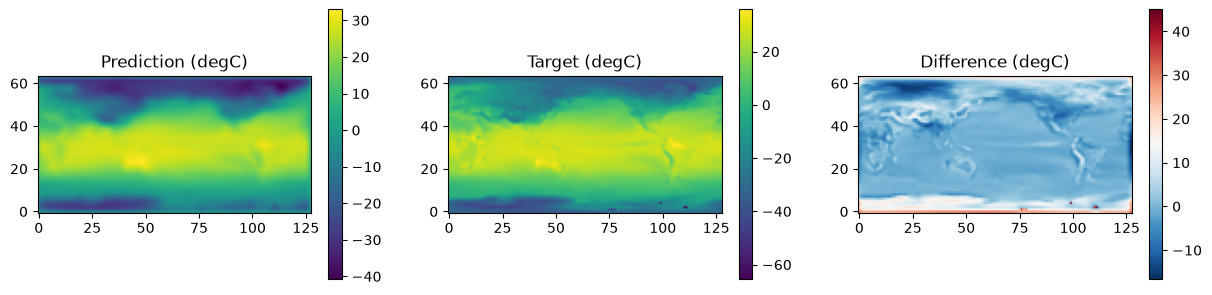

In [8]:
x, y = data_preparation[val_start]

model.eval()
with torch.no_grad():
    prediction = model(torch.tensor(x[None], dtype=torch.float32))[0, 0].numpy()

def to_degc(values):
    return values * norm_std + norm_mean

fields = {
    'Prediction': to_degc(prediction),
    'Target': to_degc(y[0]),
}
fields['Difference'] = fields['Prediction'] - fields['Target']

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (title, field) in zip(axes, fields.items()):
    image = ax.imshow(field, origin='lower', cmap='RdBu_r' if title == 'Difference' else 'viridis')
    ax.set_title(f'{title} (degC)')
    fig.colorbar(image, ax=ax)
plt.show()